# Phase 9 Validation & Analysis

Authoritative validation notebook for `data/processed/scores/complexity_index_v1.csv` (self-contained — re-derives team-size correlation and manual outlier review fresh rather than citing `notebooks/score_design.ipynb`). Covers score distribution, technical-vs-practical relationship, complexity by batch/status/industry, a full correlation heatmap, team-size correlation, targeted validation questions, manual outlier review, and findings, per `docs/superpowers/specs/2026-07-13-phase9-validation-analysis-design.md`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO_ROOT))

scores_df = pd.read_csv(REPO_ROOT / "data" / "processed" / "scores" / "complexity_index_v1.csv")
features_df = pd.read_parquet(REPO_ROOT / "data" / "processed" / "features" / "complexity_features.parquet")
companies_df = pd.read_csv(REPO_ROOT / "data" / "processed" / "step3_enriched" / "companies_enriched.csv")
industries_df = pd.read_csv(REPO_ROOT / "data" / "processed" / "step3_enriched" / "industries_enriched.csv")

merged = scores_df.merge(companies_df[["id", "teamSize"]], on="id", how="left")
merged["log_team_size"] = np.log1p(merged["teamSize"])

feature_cols = [c for c in features_df.columns if c not in ("id", "slug", "name", "batch", "status")]
merged = merged.merge(features_df[["id"] + feature_cols], on="id", how="left")

industry_merged = scores_df.merge(industries_df, on="id", how="left")

merged.shape, industry_merged.shape

((4844, 24), (8857, 15))

## 1. Score Distribution

Objectives doc target: standard deviation ≥ 15 points (avoid clustering).

array([[<Axes: title={'center': 'complexity_score'}>,
        <Axes: title={'center': 'technical_score'}>,
        <Axes: title={'center': 'practical_score'}>]], dtype=object)

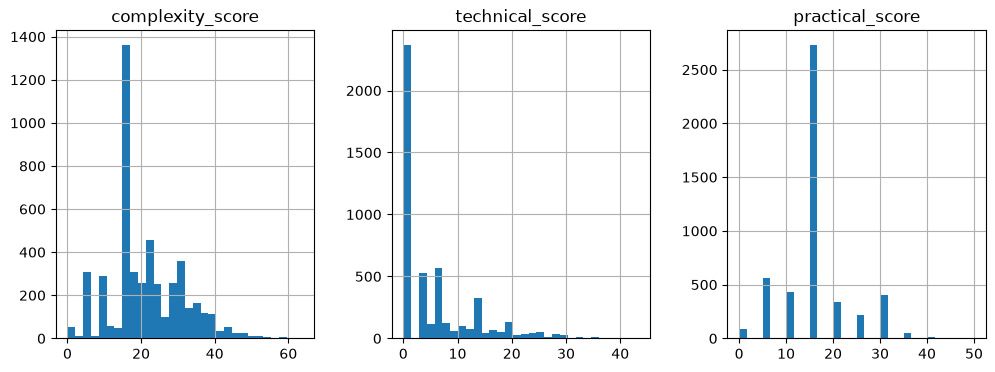

In [2]:
merged[["complexity_score", "technical_score", "practical_score"]].hist(bins=30, figsize=(12, 4), layout=(1, 3))

In [3]:
std = merged["complexity_score"].std()
print(f"complexity_score std: {std:.2f} (target: >= 15)")
merged["complexity_score"].describe()

complexity_score std: 10.11 (target: >= 15)


count    4844.000000
mean       21.029149
std        10.108302
min         0.000000
25%        15.000000
50%        18.800000
75%        28.300000
max        63.800000
Name: complexity_score, dtype: float64

## 2. Technical vs Practical

Checks whether the two 0-50 sub-scores move together or measure independent dimensions of complexity, as the rubric intends.

Correlation between technical_score and practical_score: -0.049


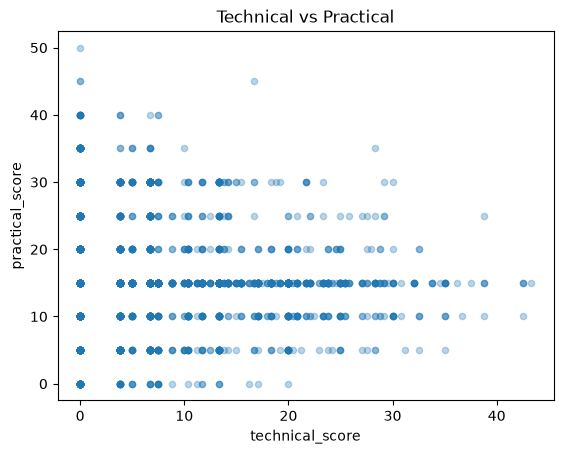

In [4]:
merged.plot(kind="scatter", x="technical_score", y="practical_score", alpha=0.3, title="Technical vs Practical")
tp_corr = merged["technical_score"].corr(merged["practical_score"])
print(f"Correlation between technical_score and practical_score: {tp_corr:.3f}")